In [6]:
import pandas as pd
import numpy as np
df = pd.read_csv("Telco_Customer_Churn_Dataset .csv")
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(df.shape)

(7043, 21)


In [7]:
# Check the dataset
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df['TenureSegment'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 36, 72],
    labels=[
        'New Customer',
        'Mid-Term Customer',
        'Long-Term Customer'])
tenure_segment_count = (
    df['TenureSegment']
    .value_counts()
    .sort_index())
print(tenure_segment_count)

TenureSegment
New Customer          2186
Mid-Term Customer     1856
Long-Term Customer    3001
Name: count, dtype: int64


Churn Rate by Tenure Segment:
TenureSegment
New Customer          47.438243
Mid-Term Customer     25.538793
Long-Term Customer    11.929357
Name: Churn, dtype: float64


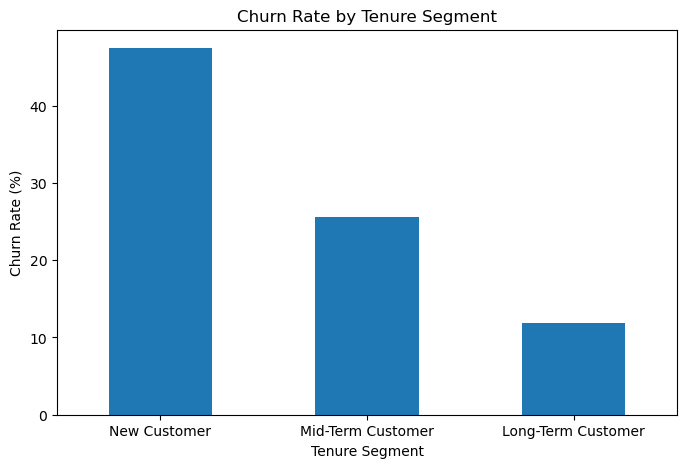

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
tenure_churn = (
    df.groupby(
        'TenureSegment',
        observed=False)['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100))
print("Churn Rate by Tenure Segment:")
print(tenure_churn)

plt.figure(figsize=(8, 5))
tenure_churn.plot(kind='bar')
plt.title('Churn Rate by Tenure Segment')
plt.xlabel('Tenure Segment')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [11]:
df['ChargeSegment'] = pd.cut(
    df['MonthlyCharges'],
    bins=[-np.inf, 50, 80, np.inf],
    labels=[
        'Low Charge',
        'Medium Charge',
        'High Charge' ])
charge_segment_count = (
    df['ChargeSegment']
    .value_counts()
    .sort_index())
print(charge_segment_count)

ChargeSegment
Low Charge       2299
Medium Charge    2078
High Charge      2666
Name: count, dtype: int64


Churn Rate by Monthly Charge Segment:
ChargeSegment
Low Charge       15.702479
Medium Charge    28.970164
High Charge      33.983496
Name: Churn, dtype: float64


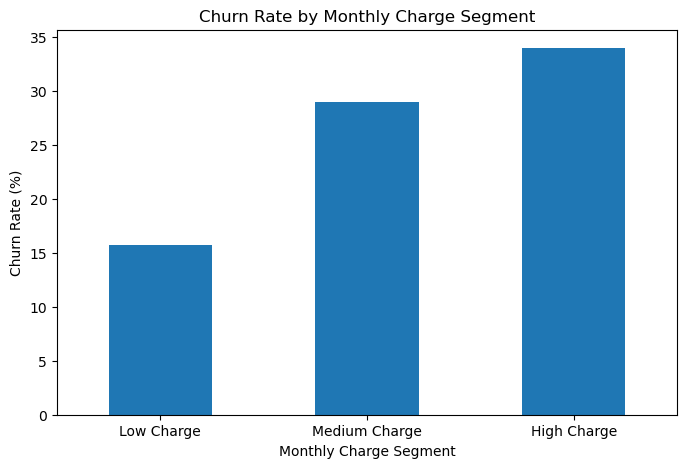

In [12]:
charge_churn = ( df.groupby(
        'ChargeSegment',
        observed=False )['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100))
print("Churn Rate by Monthly Charge Segment:")
print(charge_churn)

plt.figure(figsize=(8, 5))
charge_churn.plot(kind='bar')
plt.title('Churn Rate by Monthly Charge Segment')
plt.xlabel('Monthly Charge Segment')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [13]:
df['Contract'].value_counts()
contract_count = (
    df['Contract']
    .value_counts())
print(contract_count)

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


Churn Rate by Contract:
Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


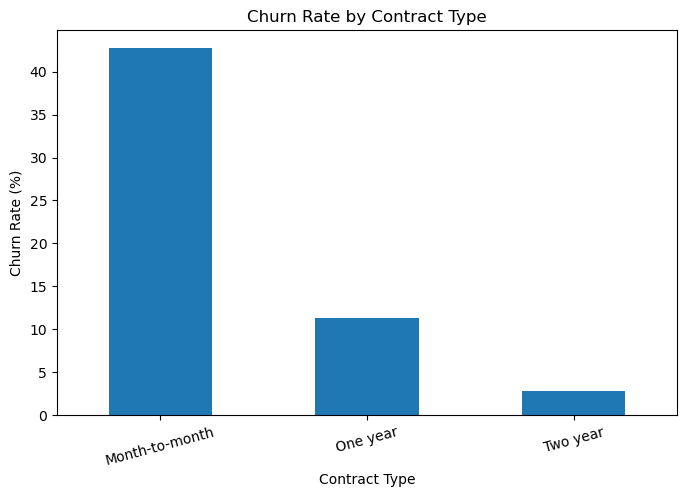

In [14]:
contract_churn = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False))
print("Churn Rate by Contract:")
print(contract_churn)

plt.figure(figsize=(8, 5))
contract_churn.plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)
plt.show()

In [15]:
segment_analysis = (
    df.groupby( [
            'TenureSegment',
            'ChargeSegment',
            'Contract'  ],
        observed=False ).agg(
        Customers=('customerID', 'count'),
        Churned=('Churn', lambda x: (x == 'Yes').sum())) .reset_index())
segment_analysis['ChurnRate'] = (
    segment_analysis['Churned'] / segment_analysis['Customers']* 100)
segment_analysis.head(20)

,TenureSegment,ChargeSegment,Contract,Customers,Churned,ChurnRate
0,New Customer,Low Charge,Month-to-month,776,278,35.824742
1,New Customer,Low Charge,One year,93,7,7.526882
2,New Customer,Low Charge,Two year,56,0,0.000000
3,New Customer,Medium Charge,Month-to-month,754,405,53.713528
4,New Customer,Medium Charge,One year,24,4,16.666667
5,New Customer,Medium Charge,Two year,10,0,0.000000
6,New Customer,High Charge,Month-to-month,464,341,73.491379
7,New Customer,High Charge,One year,7,2,28.571429
8,New Customer,High Charge,Two year,2,0,0.000000
9,Mid-Term Customer,Low Charge,Month-to-month,260,42,16.153846


In [16]:
segment_analysis_filtered = segment_analysis[
    segment_analysis['Customers'] >= 50
].copy()
segment_analysis_filtered = (
    segment_analysis_filtered.sort_values(
        'ChurnRate',
        ascending=False ))
segment_analysis_filtered.head(10)

,TenureSegment,ChargeSegment,Contract,Customers,Churned,ChurnRate
6,New Customer,High Charge,Month-to-month,464,341,73.491379
3,New Customer,Medium Charge,Month-to-month,754,405,53.713528
15,Mid-Term Customer,High Charge,Month-to-month,575,278,48.347826
0,New Customer,Low Charge,Month-to-month,776,278,35.824742
24,Long-Term Customer,High Charge,Month-to-month,426,145,34.037559
12,Mid-Term Customer,Medium Charge,Month-to-month,388,116,29.896907
21,Long-Term Customer,Medium Charge,Month-to-month,154,35,22.727273
16,Mid-Term Customer,High Charge,One year,89,19,21.348315
18,Long-Term Customer,Low Charge,Month-to-month,78,15,19.230769
25,Long-Term Customer,High Charge,One year,469,88,18.763326


In [17]:
top_segments = segment_analysis_filtered[  [
        'TenureSegment',
        'ChargeSegment',
        'Contract',
        'Customers',
        'Churned',
        'ChurnRate' ]].head(10)
top_segments

,TenureSegment,ChargeSegment,Contract,Customers,Churned,ChurnRate
6,New Customer,High Charge,Month-to-month,464,341,73.491379
3,New Customer,Medium Charge,Month-to-month,754,405,53.713528
15,Mid-Term Customer,High Charge,Month-to-month,575,278,48.347826
0,New Customer,Low Charge,Month-to-month,776,278,35.824742
24,Long-Term Customer,High Charge,Month-to-month,426,145,34.037559
12,Mid-Term Customer,Medium Charge,Month-to-month,388,116,29.896907
21,Long-Term Customer,Medium Charge,Month-to-month,154,35,22.727273
16,Mid-Term Customer,High Charge,One year,89,19,21.348315
18,Long-Term Customer,Low Charge,Month-to-month,78,15,19.230769
25,Long-Term Customer,High Charge,One year,469,88,18.763326


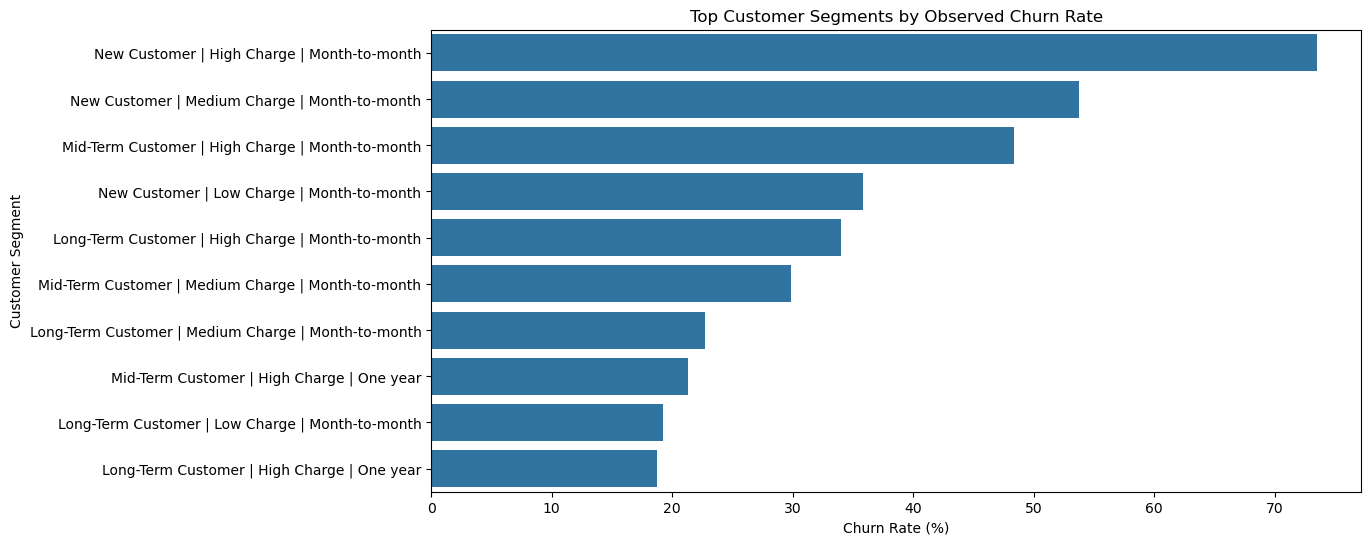

In [18]:
plot_data = segment_analysis_filtered.head(10).copy()
plot_data['Segment'] = (
    plot_data['TenureSegment'].astype(str)
    + ' | '
    + plot_data['ChargeSegment'].astype(str)
    + ' | '
    + plot_data['Contract'].astype(str))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_data,
    x='ChurnRate',
    y='Segment')
plt.title('Top Customer Segments by Observed Churn Rate')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Customer Segment')
plt.show()

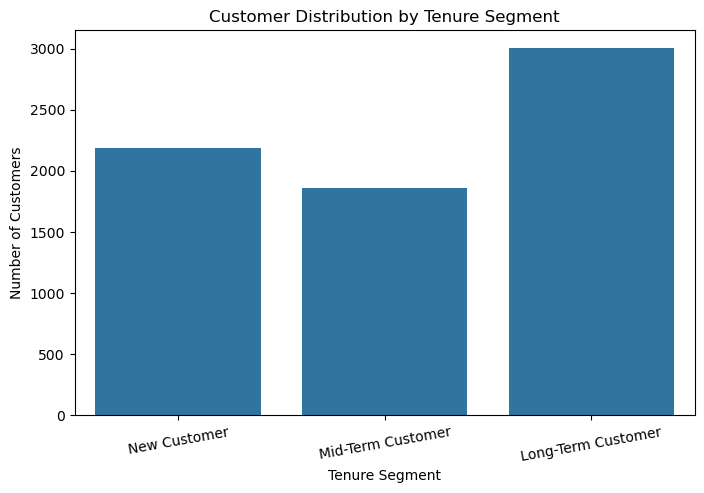

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='TenureSegment',
    order=[
        'New Customer',
        'Mid-Term Customer',
        'Long-Term Customer' ])
plt.title('Customer Distribution by Tenure Segment')
plt.xlabel('Tenure Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=10)
plt.show()

In [20]:
final_segment_summary = pd.DataFrame({
    'Segmentation Factor': [
        'Tenure',
        'Monthly Charges',
        'Contract'  ],
    'Number of Segments': [
        df['TenureSegment'].nunique(),
        df['ChargeSegment'].nunique(),
        df['Contract'].nunique() ],
    'Purpose': [
        'Identify differences across customer lifecycle stages',
        'Compare customers based on monthly spending',
        'Compare customers based on contract commitment' ]})
final_segment_summary

,Segmentation Factor,Number of Segments,Purpose
0,Tenure,3,Identify differences across customer lifecycle...
1,Monthly Charges,3,Compare customers based on monthly spending
2,Contract,3,Compare customers based on contract commitment


In [21]:
print("Total customers:", len(df))
print(  "Customers in tenure segments:",
    df['TenureSegment'].notna().sum())
print(  "Customers in charge segments:",
    df['ChargeSegment'].notna().sum())
print( "Customers with contract information:",
    df['Contract'].notna().sum())
print(  "Combined segments created:",
    len(segment_analysis))

Total customers: 7043
Customers in tenure segments: 7043
Customers in charge segments: 7043
Customers with contract information: 7043
Combined segments created: 27
